# 13 — NN encoder with an LDA head

An MLP encoder (128 -> 32 bottleneck) trained with a softmax head, which is then replaced by an LDA on
the 32-dimensional embedding (`src/nn.py`, `NNLDA`). The encoder learns a feature space shared across subjects; the
LDA head keeps the closed-form calibration of the baseline.

Calibration (`loso`): `LDA.adapt` on the embedding of the new subject's windows, no gradient steps on the device.

Same protocol as `10`: DB5 exercise 1, train on repetitions 1–4, test on 5–6, every regime. Writes `runs/notebooks/nn_lda.json` for `15`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from src import report

if Path.cwd().name == "notebooks":
    os.chdir("..")

In [2]:
FEATURES = {}
DECODER = {"decoder": {"name": "nn_lda", "params": {}}}
cfg, *data = report.features(FEATURES)
X, y, columns, info = data
print(f"{len(y)} windows x {X.shape[1]} features")

140145 windows x 48 features


## Every regime

In [3]:
summary = report.run_regimes({**FEATURES, **DECODER}, data)
latency = report.latency_us({**FEATURES, **DECODER}, data)
report.save(DECODER["decoder"]["name"], summary, latency)
print(f"decoder latency: {latency:.0f} µs per window")

per_user balanced 0.685 | macro-F1 0.692 | 34 s


pooled   balanced 0.568 | macro-F1 0.581 | 19 s


loso     balanced 0.364 | macro-F1 0.378 | 223 s


decoder latency: 14 µs per window


Against the LDA baseline (from `10`):

In [4]:
summaries = report.load_all()
names = [n for n in ("lda", DECODER["decoder"]["name"]) if n in summaries]
report.table({n: summaries[n] for n in names}).round(3)

accuracy  balanced_accuracy  macro_f1  worst_user_balanced  \
decoder regime                                                                 
lda     per_user     0.810              0.643     0.653                0.566   
        pooled       0.730              0.461     0.467                0.291   
        loso         0.701              0.389     0.393                0.234   
nn_lda  per_user     0.834              0.685     0.692                0.595   
        pooled       0.778              0.568     0.581                0.374   
        loso         0.692              0.364     0.378                0.228   

                  switches_per_s  latency_us  evaluation_s  
decoder regime                                              
lda     per_user           2.468       7.375         0.940  
        pooled             3.519       7.375         0.156  
        loso               3.690       7.375         1.876  
nn_lda  per_user           2.360      14.500        33.819  
        pooled             3.490      14.500        18.931  
        loso               4.430      14.500       223.461

## Calibration effort

Dashed: a new decoder per subject from *n* seconds per class. Solid: the decoder of the other nine subjects, adapted with them.

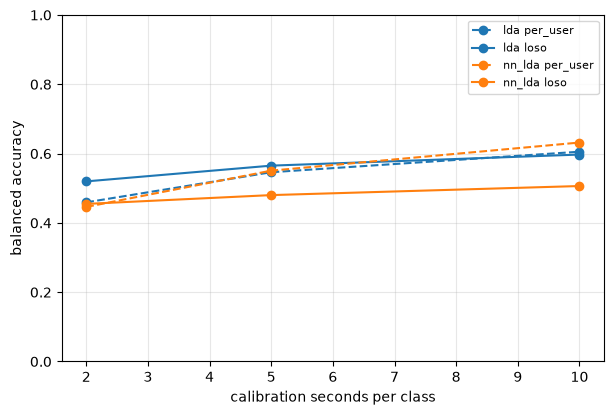

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
report.plot_calibration(ax, {n: summaries[n] for n in names})

## Confusions (per_user)

per_user    0.936
pooled      0.920
loso        0.916
Name: rest recall, dtype: float64

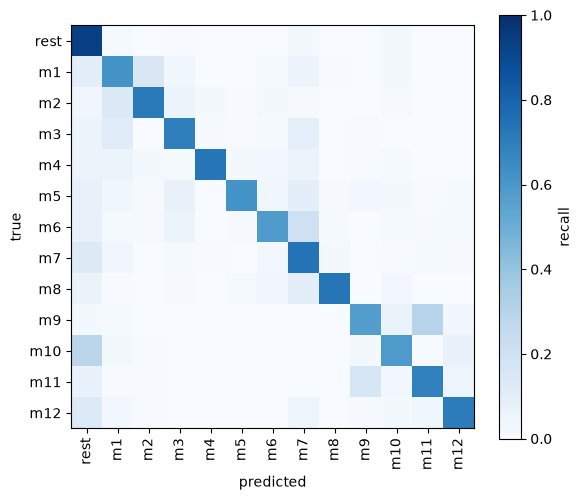

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = report.plot_confusion(ax, summary["per_user"]["y_true"], summary["per_user"]["y_pred"], info["label_names"])
fig.colorbar(im, label="recall")
pd.Series({regime: s["recall"]["rest"] for regime, s in summary.items()}, name="rest recall").round(3)